In [224]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.io as scio
from scipy.sparse import issparse
import matplotlib.pyplot as plt
import os
import matplotlib as mpl
from sklearn.cluster import KMeans
from pathlib import Path
import sklearn.metrics as metrics

In [225]:
import os
os.chdir('/root/autodl-tmp/Spagc')

In [226]:
from model.util import mclust_R

In [227]:
%matplotlib inline

In [250]:
data_path = "data"
data_name = '3D_Hippo'
dataset_name = '3D'
save_data_path = 'Results/Figure'
input_dir = os.path.join(data_path, dataset_name, data_name)
output_dir = os.path.join(save_data_path, dataset_name, data_name)
os.makedirs(output_dir, exist_ok=True)

In [251]:
from model.util import mclust_R

In [252]:
output_dir

'Results/Figure/3D/3D_Hippo'

In [253]:
adata=sc.read(os.path.join(output_dir, f'{data_name}_result_raw.h5ad'))

In [242]:
adata

AnnData object with n_obs × n_vars = 10908 × 9420
    obs: 'X', 'Y', 'Z', 'Section_id', 'mclust'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'Section_id_colors', 'hvg', 'log1p', 'mclust_colors', 'neighbors', 'umap'
    obsm: 'Spagc', 'X_umap', 'spatial'
    obsp: 'connectivities', 'distances'

In [202]:
#d62728--red
#ff7f0e--yellow
#2ca02c--green
#1f77b4--blue
adata.uns['mclust_colors']=['#ff7f0e','#d62728',  '#1f77b4','#2ca02c']

In [203]:
adata.uns['Section_id_colors'] = ['#02899A', '#0E994D', '#86C049', '#FBB21F', '#F48022', '#DA5326', '#BA3326']

/root/miniconda3/envs/deepst_env/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/root/miniconda3/envs/deepst_env/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


[<Axes: title={'center': 'mclust'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'Section_id'}, xlabel='UMAP1', ylabel='UMAP2'>]

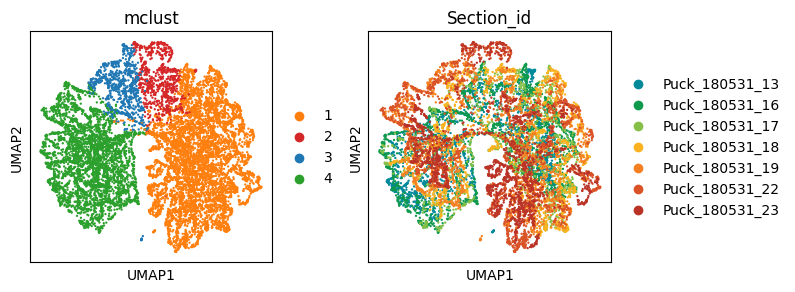

In [204]:
plt.rcParams["figure.figsize"] = (3, 3)
sc.pl.umap(adata, color=['mclust', 'Section_id'], show=False)
# plt.savefig(os.path.join(output_dir, f'3D_Hippo_pred_umap_domain.svg'), bbox_inches='tight', dpi=300)

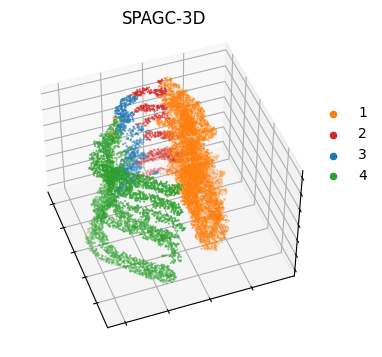

In [205]:
fig = plt.figure(figsize=(4, 4))
ax1 = plt.axes(projection='3d')


for it, label in enumerate(np.unique(adata.obs['mclust'])):
    temp_Coor = adata.obs.loc[adata.obs['mclust']==label, :]
    temp_xd = temp_Coor['X']
    temp_yd = temp_Coor['Y']
    temp_zd = temp_Coor['Z']
    ax1.scatter3D(temp_xd, temp_yd, temp_zd, c=adata.uns['mclust_colors'][it],s=0.2, marker="o", label=label)

ax1.set_xlabel('')
ax1.set_ylabel('')
ax1.set_zlabel('')

ax1.set_xticklabels([])
ax1.set_yticklabels([])
ax1.set_zticklabels([])

plt.legend(bbox_to_anchor=(1.2,0.8), markerscale=10, frameon=False)
plt.title('SPAGC-3D')

ax1.elev = 45
ax1.azim = -20

# plt.show()
# plt.savefig(os.path.join(output_dir, f'3D_Hippo_pred_3D_domain.svg'), bbox_inches='tight', dpi=300)

In [ ]:
output_dir = os.path.join(save_data_path, dataset_name, '2D Hippo')
os.makedirs(output_dir, exist_ok=True)

In [ ]:
z_f=scio.loadmat(os.path.join('Results/Data', dataset_name, '2D Hippo', f'model_output.mat'))
z_f=z_f['data']
z_f.shape

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=30, random_state=42)
z_f = pca.fit_transform(z_f)
adata.obsm['Spagc'] = z_f

In [ ]:
sc.pp.neighbors(adata, use_rep='Spagc')
sc.tl.umap(adata)

In [ ]:
num_cluster = 4
adata = mclust_R(adata, num_cluster, used_obsm='Spagc')

In [ ]:
adata.write(os.path.join(output_dir, f'2D Hippo_result_raw.h5ad'), compression="gzip")

In [259]:
adata=sc.read(os.path.join(output_dir, f'{data_name}_result_raw.h5ad'))

In [185]:
adata.uns['mclust_colors']

array(['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'], dtype=object)

In [186]:
adata.uns['Section_id_colors'] = ['#02899A', '#0E994D', '#86C049', '#FBB21F', '#F48022', '#DA5326', '#BA3326']

/root/miniconda3/envs/deepst_env/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/root/miniconda3/envs/deepst_env/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


[<Axes: title={'center': 'mclust'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'Section_id'}, xlabel='UMAP1', ylabel='UMAP2'>]

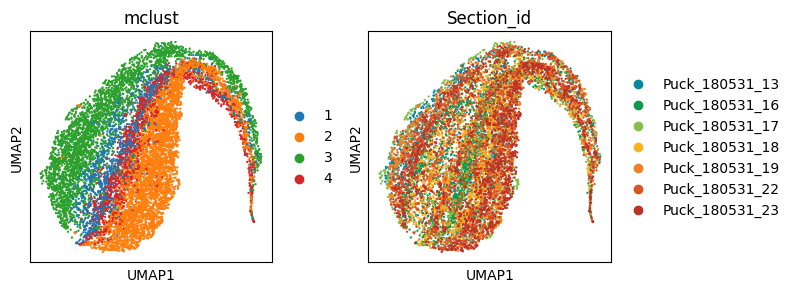

In [187]:
plt.rcParams["figure.figsize"] = (3, 3)
sc.pl.umap(adata, color=['mclust', 'Section_id'], show=False)
# plt.savefig(os.path.join(output_dir, f'3D_Hippo_pred_umap_domain.svg'), bbox_inches='tight', dpi=300)

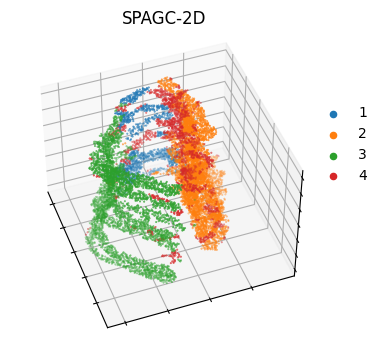

In [189]:
fig = plt.figure(figsize=(4, 4))
ax1 = plt.axes(projection='3d')
for it, label in enumerate(np.unique(adata.obs['mclust'])):
    temp_Coor = adata.obs.loc[adata.obs['mclust']==label, :]
    temp_xd = temp_Coor['X']
    temp_yd = temp_Coor['Y']
    temp_zd = temp_Coor['Z']
    ax1.scatter3D(temp_xd, temp_yd, temp_zd, c=adata.uns['mclust_colors'][it],s=0.2, marker="o", label=label)

ax1.set_xlabel('')
ax1.set_ylabel('')
ax1.set_zlabel('')

ax1.set_xticklabels([])
ax1.set_yticklabels([])
ax1.set_zticklabels([])

plt.legend(bbox_to_anchor=(1.2,0.8), markerscale=10, frameon=False)
plt.title('SPAGC-2D')

ax1.elev = 45
ax1.azim = -20

# plt.show()
# plt.savefig(os.path.join(output_dir, f'3D_Hippo_pred_2D_domain.svg'), bbox_inches='tight', dpi=300)

In [157]:
adata=sc.read(os.path.join(output_dir, f'{data_name}_result_raw.h5ad'))

In [93]:
adata

AnnData object with n_obs × n_vars = 10908 × 9420
    obs: 'X', 'Y', 'Z', 'Section_id', 'mclust'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'neighbors', 'umap'
    obsm: 'Spagc', 'X_umap', 'spatial'
    obsp: 'connectivities', 'distances'

In [94]:
section_colors = ['#02899A', '#0E994D', '#86C049', '#FBB21F', '#F48022', '#DA5326', '#BA3326']

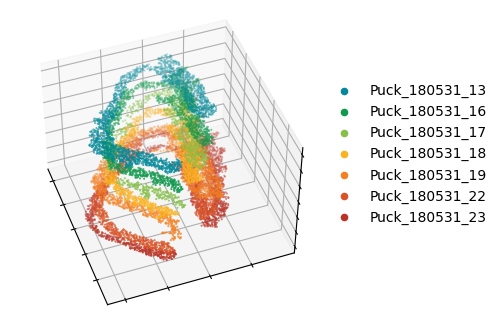

In [95]:
fig = plt.figure(figsize=(4, 4))
ax1 = plt.axes(projection='3d')
for it, label in enumerate(np.unique(adata.obs['Section_id'])):
    temp_Coor = adata.obs.loc[adata.obs['Section_id']==label, :]
    temp_xd = temp_Coor['X']
    temp_yd = temp_Coor['Y']
    temp_zd = temp_Coor['Z']
    ax1.scatter3D(temp_xd, temp_yd, temp_zd, c=section_colors[it],s=0.2, marker="o", label=label)

ax1.set_xlabel('')
ax1.set_ylabel('')
ax1.set_zlabel('')

ax1.set_xticklabels([])
ax1.set_yticklabels([])
ax1.set_zticklabels([])

plt.legend(bbox_to_anchor=(1,0.8), markerscale=10, frameon=False)

ax1.elev = 45
ax1.azim = -20

plt.show()

In [260]:
sc.pp.pca(adata, n_comps=30)

In [261]:
adata

AnnData object with n_obs × n_vars = 10908 × 9420
    obs: 'X', 'Y', 'Z', 'Section_id', 'mclust'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'neighbors', 'umap', 'pca'
    obsm: 'Spagc', 'X_umap', 'spatial', 'X_pca'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [98]:
sc.pp.neighbors(adata, use_rep='X_pca')
sc.tl.umap(adata)

/root/miniconda3/envs/deepst_env/lib/python3.9/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/root/miniconda3/envs/deepst_env/lib/python3.9/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/root/miniconda3/envs/deepst_env/lib/python3.9/site-packages/umap/distances.

In [99]:
adata

AnnData object with n_obs × n_vars = 10908 × 9420
    obs: 'X', 'Y', 'Z', 'Section_id', 'mclust'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'neighbors', 'umap', 'pca'
    obsm: 'Spagc', 'X_umap', 'spatial', 'X_pca'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [262]:
num_cluster = 4
adata = mclust_R(adata, num_cluster, used_obsm='X_pca')

fitting ...
  |======================================================================| 100%


/root/miniconda3/envs/deepst_env/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/root/miniconda3/envs/deepst_env/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


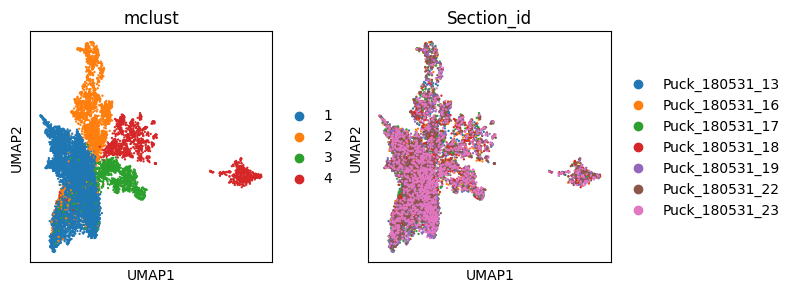

In [106]:
plt.rcParams["figure.figsize"] = (3, 3)
sc.pl.umap(adata, color=['mclust', 'Section_id'], show=False)
plt.savefig(os.path.join(output_dir, f'3D_Hippo_SCANPY_pred_umap_domain.svg'), bbox_inches='tight', dpi=300)

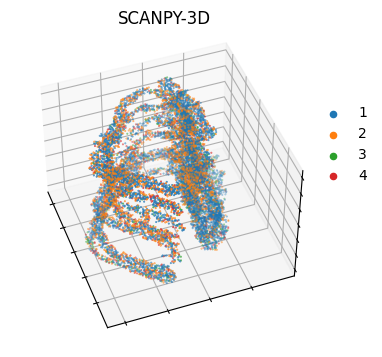

In [107]:
fig = plt.figure(figsize=(4, 4))
ax1 = plt.axes(projection='3d')
for it, label in enumerate(np.unique(adata.obs['mclust'])):
    temp_Coor = adata.obs.loc[adata.obs['mclust']==label, :]
    temp_xd = temp_Coor['X']
    temp_yd = temp_Coor['Y']
    temp_zd = temp_Coor['Z']
    ax1.scatter3D(temp_xd, temp_yd, temp_zd, c=adata.uns['mclust_colors'][it],s=0.2, marker="o", label=label)

ax1.set_xlabel('')
ax1.set_ylabel('')
ax1.set_zlabel('')

ax1.set_xticklabels([])
ax1.set_yticklabels([])
ax1.set_zticklabels([])

plt.legend(bbox_to_anchor=(1.2,0.8), markerscale=10, frameon=False)
plt.title('SCANPY-3D')

ax1.elev = 45
ax1.azim = -20

# plt.show()
plt.savefig(os.path.join(output_dir, f'3D_Hippo_SCANPY_pred_3D_domain.svg'), bbox_inches='tight', dpi=300)

In [263]:
adata

AnnData object with n_obs × n_vars = 10908 × 9420
    obs: 'X', 'Y', 'Z', 'Section_id', 'mclust'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'neighbors', 'umap', 'pca'
    obsm: 'Spagc', 'X_umap', 'spatial', 'X_pca'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [264]:
marker_genes_dict = {
    'CA1sp': ['Bcl11b','Itpka'], 
    'CA2sp': ['Pcp4','Amigo2'], 
    'CA3sp': ['Cpne4','Hs3st4'],
    'Dentate gyrus':['Lrrtm4']
}

In [265]:
# adata.obs['mclust']=adata.obs['mclust'].astype(str)
adata.obs['mclust']

AAAAACAACCAAT-13    4
AAAAGTCCATTAT-13    3
AAACAACGCGCGA-13    1
AAACAATTCAATA-13    3
AAACACGCTGCCC-13    3
                   ..
TTTTACCCCTAGA-23    3
TTTTCGAGTCTGA-23    1
TTTTCGGGCTGCG-23    1
TTTTGCTACTTAG-23    1
TTTTTGGTATCTT-23    1
Name: mclust, Length: 10908, dtype: category
Categories (4, int64): [1, 2, 3, 4]

In [266]:
adata.obs['mclust'] = [str(item) for item in adata.obs['mclust']]

In [267]:
adata.obs['mclust']

AAAAACAACCAAT-13    4
AAAAGTCCATTAT-13    3
AAACAACGCGCGA-13    1
AAACAATTCAATA-13    3
AAACACGCTGCCC-13    3
                   ..
TTTTACCCCTAGA-23    3
TTTTCGAGTCTGA-23    1
TTTTCGGGCTGCG-23    1
TTTTGCTACTTAG-23    1
TTTTTGGTATCTT-23    1
Name: mclust, Length: 10908, dtype: object

categories: 1, 2, 3, etc.
var_group_labels: CA1sp, CA2sp, CA3sp, etc.


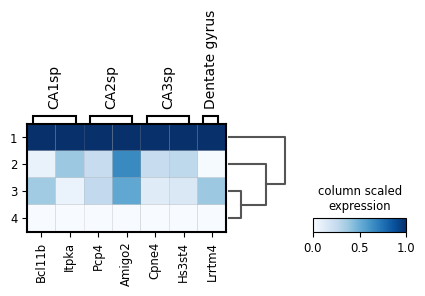

In [268]:
sc.pl.matrixplot(adata, marker_genes_dict, 'mclust', dendrogram=True,cmap='Blues', standard_scale='var', colorbar_title='column scaled\nexpression',show=False)
plt.savefig(os.path.join(output_dir, f'3D_Hippo_SCANPY_3D_marker_gene.svg'), bbox_inches='tight', dpi=300)